# NN-Interp: learning multiplication

We train a small **2 → 4 → 2 → 1** network (25 trainable parameters) on independent uniform inputs in $[-2, 2]^2$, with target $xy$. Both hidden layers use `tanh`; the output is linear. Our goal is **held-out MSE < 0.001**.

We plot the learned surface at several training stages, print five activation examples from each of four cases, and fit **4 → 1** and **2 → 1** linear probes to the frozen hidden layers.

Run the cells from top to bottom. Only PyTorch and Matplotlib are required. Training uses Adam followed by full-batch L-BFGS refinement; it can take a few minutes on a CPU.

In [1]:
# Run this once if the packages are missing, then restart the kernel:
# %pip install torch matplotlib

In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt

# One thread avoids overhead for these tiny matrices.
torch.set_num_threads(1)
torch.manual_seed(42)
plt.rcParams["figure.figsize"] = (8, 4)


def sample_inputs(n, generator=None):
    return 4 * torch.rand(n, 2, generator=generator) - 2


def product(inputs):
    return inputs[:, :1] * inputs[:, 1:2]


train_x = sample_inputs(4096)
validation_x = sample_inputs(4096)
# An independent generator keeps the final test set separate from tuning.
test_x = sample_inputs(16384, generator=torch.Generator().manual_seed(2026))
train_y = product(train_x)
validation_y = product(validation_x)
test_y = product(test_x)

## Train the multiplication network

`activations()` returns the values **after** each hidden layer's `tanh`. Adam learns the overall shape, then L-BFGS refines the same 25 parameters. Neither optimizer uses validation or test examples for its gradients.

Snapshots show MSE on a fixed held-out **validation** set used during experimentation. The independent final **test** set is evaluated after training. A random test-set MSE measures average error, not a bound on error at every input.

Step 0: held-out validation MSE = 2.357946


Adam step 100: held-out validation MSE = 0.294962


Adam step 500: held-out validation MSE = 0.026764


Adam step 2000: held-out validation MSE = 0.005740


Adam step 6000: held-out validation MSE = 0.001360


Adam step 12000: held-out validation MSE = 0.000718


After L-BFGS: held-out validation MSE = 0.000718

Parameters: 25
Final held-out test MSE: 0.000724
Final held-out test MAE: 0.019585
MSE < 0.001: True


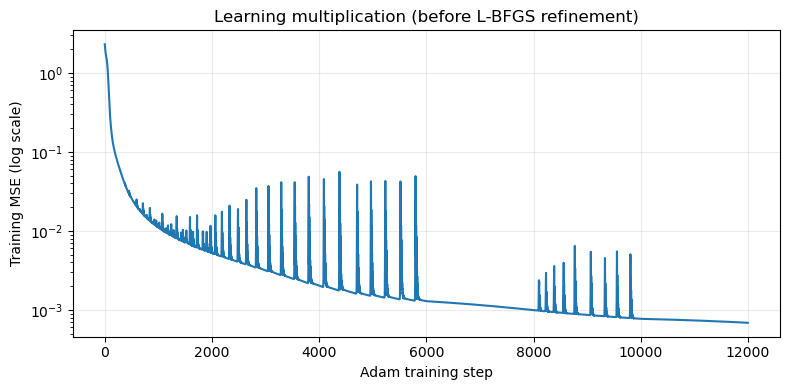

In [3]:
class MultiplicationNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden1 = nn.Linear(2, 4)
        self.hidden2 = nn.Linear(4, 2)
        self.output = nn.Linear(2, 1)

    def activations(self, inputs):
        h1 = torch.tanh(self.hidden1(inputs))
        h2 = torch.tanh(self.hidden2(h1))
        return h1, h2

    def forward(self, inputs):
        _, h2 = self.activations(inputs)
        return self.output(h2)


model = MultiplicationNet()
loss_fn = nn.MSELoss()
losses = []
snapshots = []
snapshot_steps = {0, 100, 500, 2000, 6000, 12000}
stage_axis = torch.linspace(-2, 2, 41)
stage_xx, stage_yy = torch.meshgrid(stage_axis, stage_axis, indexing="xy")
stage_grid = torch.stack([stage_xx.flatten(), stage_yy.flatten()], dim=1)


@torch.no_grad()
def save_snapshot(label):
    mse = loss_fn(model(validation_x), validation_y).item()
    surface = model(stage_grid).reshape(stage_xx.shape).clone()
    snapshots.append((label, mse, surface))
    print(f"{label}: held-out validation MSE = {mse:.6f}")


optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=[6000, 10000], gamma=0.3
)
model.train()
save_snapshot("Step 0")
for step in range(1, 12001):
    loss = loss_fn(model(train_x), train_y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    scheduler.step()
    losses.append(loss.item())
    if step in snapshot_steps:
        save_snapshot(f"Adam step {step}")

# Refine the fit without adding neurons or changing the activation function.
optimizer = torch.optim.LBFGS(
    model.parameters(), max_iter=1500, line_search_fn="strong_wolfe",
    tolerance_grad=1e-9, tolerance_change=1e-12,
)


def refine_closure():
    optimizer.zero_grad()
    loss = loss_fn(model(train_x), train_y)
    loss.backward()
    return loss


optimizer.step(refine_closure)
model.eval()
save_snapshot("After L-BFGS")
with torch.no_grad():
    test_prediction = model(test_x)
    test_mse = loss_fn(test_prediction, test_y).item()
    print(f"\nParameters: {sum(p.numel() for p in model.parameters())}")
    print(f"Final held-out test MSE: {test_mse:.6f}")
    print(f"Final held-out test MAE: {(test_prediction - test_y).abs().mean().item():.6f}")
    print(f"MSE < 0.001: {test_mse < 0.001}")

plt.semilogy(losses)
plt.xlabel("Adam training step")
plt.ylabel("Training MSE (log scale)")
plt.title("Learning multiplication (before L-BFGS refinement)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Watch the surface form

Each panel uses the same axes, viewing angle, and color scale. Its title gives the training stage and MSE on the **same held-out validation set**. The last panel shows the true multiplication surface for comparison.

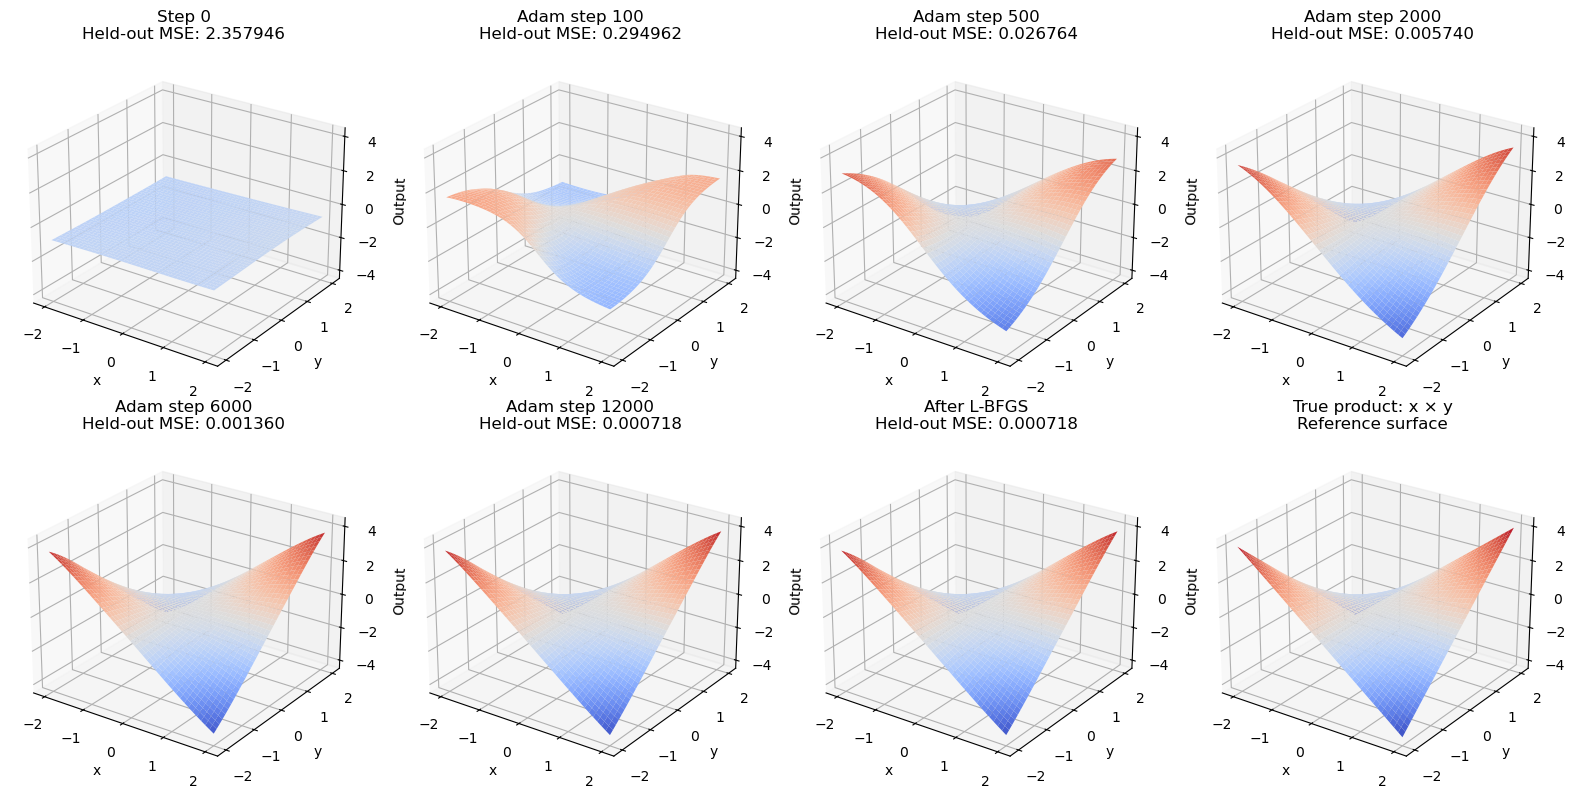

In [4]:
fig = plt.figure(figsize=(16, 8))
for i, (label, mse, surface) in enumerate(snapshots):
    ax = fig.add_subplot(2, 4, i + 1, projection="3d")
    ax.plot_surface(stage_xx.numpy(), stage_yy.numpy(), surface.numpy(),
                    cmap="coolwarm", vmin=-4, vmax=4, linewidth=0)
    ax.set(xlabel="x", ylabel="y", zlabel="Output", zlim=(-4.5, 4.5),
           title=f"{label}\nHeld-out MSE: {mse:.6f}")
    ax.view_init(elev=25, azim=-55)

ax = fig.add_subplot(2, 4, 8, projection="3d")
ax.plot_surface(stage_xx.numpy(), stage_yy.numpy(),
                (stage_xx * stage_yy).numpy(), cmap="coolwarm",
                vmin=-4, vmax=4, linewidth=0)
ax.set(xlabel="x", ylabel="y", zlabel="Output", zlim=(-4.5, 4.5),
       title="True product: x × y\nReference surface")
ax.view_init(elev=25, azim=-55)
plt.tight_layout()
plt.show()

## Inspect the four cases

1. Both inputs are in $[-1, 1]$.
2. Both inputs are in $[-2, -1] \cup [1, 2]$ (sample signs independently).
3. $x = 0$, with $y$ uniform on $[-2, 2]$.
4. $y = 0$, with $x$ uniform on $[-2, 2]$.

These cases are diagnostic slices, not a partition of the whole square: mixed inner/outer inputs are still included in training and the overall test set. The origin belongs to both zero-input slices.

Activation signs, saturation near ±1, and changes under input sign flips may suggest patterns. A neuron's activation alone does not establish what computation it performs.

In [5]:
def make_cases(n, seed):
    generator = torch.Generator().manual_seed(seed)
    inner = 2 * torch.rand(n, 2, generator=generator) - 1
    signs = 2 * torch.randint(0, 2, (n, 2), generator=generator) - 1
    outer = signs * (1 + torch.rand(n, 2, generator=generator))
    x_zero = 4 * torch.rand(n, 2, generator=generator) - 2
    x_zero[:, 0] = 0
    y_zero = 4 * torch.rand(n, 2, generator=generator) - 2
    y_zero[:, 1] = 0
    return {"Both inner": inner, "Both outer": outer,
            "x = 0": x_zero, "y = 0": y_zero}


def vector_string(values):
    return "[" + ", ".join(f"{v:+.3f}" for v in values.tolist()) + "]"


examples = make_cases(5, seed=123)
with torch.no_grad():
    for name, inputs in examples.items():
        h1, h2 = model.activations(inputs)
        predictions = model(inputs)
        print(f"\n{name}")
        for i in range(len(inputs)):
            print(f"x={inputs[i, 0]:+.3f}  y={inputs[i, 1]:+.3f}  "
                  f"xy={product(inputs)[i, 0]:+.3f}  pred={predictions[i, 0]:+.3f}")
            print(f"  h1={vector_string(h1[i])}  h2={vector_string(h2[i])}")


Both inner
x=-0.408  y=+0.033  xy=-0.014  pred=-0.059
  h1=[-0.193, -0.523, +0.074, -0.875]  h2=[+0.043, -0.251]
x=-0.497  y=+0.377  xy=-0.187  pred=-0.225
  h1=[-0.136, -0.535, +0.223, -0.836]  h2=[-0.035, -0.137]
x=-0.852  y=+0.733  xy=-0.625  pred=-0.620
  h1=[-0.072, -0.508, +0.441, -0.741]  h2=[-0.160, +0.014]
x=-0.727  y=-0.795  xy=+0.578  pred=+0.585
  h1=[-0.316, -0.402, -0.113, -0.906]  h2=[+0.182, -0.368]
x=-0.632  y=+0.453  xy=-0.286  pred=-0.314
  h1=[-0.121, -0.520, +0.291, -0.811]  h2=[-0.070, -0.089]

Both outer
x=+1.854  y=+1.593  xy=+2.953  pred=+2.896
  h1=[+0.026, -0.841, -0.132, -0.936]  h2=[+0.355, -0.137]
x=-1.637  y=+1.983  xy=-3.245  pred=-3.268
  h1=[+0.148, -0.481, +0.828, -0.234]  h2=[-0.531, +0.096]
x=-1.274  y=+1.658  xy=-2.114  pred=-2.111
  h1=[+0.089, -0.513, +0.738, -0.450]  h2=[-0.407, +0.136]
x=-1.278  y=+1.857  xy=-2.373  pred=-2.402
  h1=[+0.122, -0.528, +0.769, -0.395]  h2=[-0.444, +0.137]
x=+1.899  y=-1.039  xy=-1.973  pred=-1.991
  h1=[-0.390, -

## Fit linear interpreting models

The first probe is `nn.Linear(4, 1)` and the second is `nn.Linear(2, 1)`. Each is trained to reproduce the **network's predictions**, rather than the true product. We detach the hidden activations so probe training cannot change the original network. We use new training inputs and keep the earlier test inputs held out.

Since these are small linear regression problems, PyTorch's L-BFGS optimizer converges quickly with full batches. We report both probe-to-network MSE (fidelity) and probe-to-product MSE (task accuracy).

The second probe has exactly the same inputs and form as the original output layer, so high fidelity is expected. The first probe tests how much of the network's prediction is already linearly readable before the second nonlinear layer. Neither probe proves a causal explanation of the network.

In [6]:
torch.manual_seed(7)
probe_train_x = sample_inputs(4096)
with torch.no_grad():
    probe_features = model.activations(probe_train_x)
    probe_targets = model(probe_train_x)


def fit_probe(features, targets):
    probe = nn.Linear(features.shape[1], 1)
    optimizer = torch.optim.LBFGS(
        probe.parameters(), lr=1.0, max_iter=200,
        tolerance_grad=1e-10, tolerance_change=1e-12,
        line_search_fn="strong_wolfe",
    )

    def closure():
        optimizer.zero_grad()
        loss = loss_fn(probe(features), targets)
        loss.backward()
        return loss

    optimizer.step(closure)
    probe.eval()
    return probe


probe1 = fit_probe(probe_features[0], probe_targets)
probe2 = fit_probe(probe_features[1], probe_targets)

for name, probe in [("Hidden layer 1", probe1), ("Hidden layer 2", probe2)]:
    print(f"{name}: weights={vector_string(probe.weight.detach()[0])}, "
          f"bias={probe.bias.item():+.3f}")

Hidden layer 1: weights=[+30.523, +20.565, -7.732, -13.714], bias=+5.306
Hidden layer 2: weights=[+8.013, +4.012], bias=+0.606


In [7]:
evaluation_cases = {"Whole square": test_x, **make_cases(1024, seed=456)}
print(f"{'Case':<16} {'NN vs xy':>12} {'P1 vs NN':>12} {'P1 vs xy':>12} "
      f"{'P2 vs NN':>12} {'P2 vs xy':>12}")

with torch.no_grad():
    for name, inputs in evaluation_cases.items():
        target = product(inputs)
        prediction = model(inputs)
        h1, h2 = model.activations(inputs)
        p1, p2 = probe1(h1), probe2(h2)
        errors = [loss_fn(a, b).item() for a, b in [
            (prediction, target), (p1, prediction), (p1, target),
            (p2, prediction), (p2, target),
        ]]
        print(f"{name:<16}" + "".join(f"{error:12.6f}" for error in errors))

    print("\nFive-example predictions (same inputs as the activation printout):")
    for name, inputs in examples.items():
        h1, h2 = model.activations(inputs)
        print(f"\n{name}")
        print("     x       y      xy      NN      P1      P2")
        rows = torch.cat([inputs, product(inputs), model(inputs),
                          probe1(h1), probe2(h2)], dim=1)
        for row in rows:
            print(" ".join(f"{value:+7.3f}" for value in row.tolist()))

Case                 NN vs xy     P1 vs NN     P1 vs xy     P2 vs NN     P2 vs xy
Whole square        0.000724    0.022701    0.023284    0.000000    0.000724
Both inner          0.000533    0.023750    0.020249    0.000000    0.000532
Both outer          0.001625    0.044697    0.048898    0.000000    0.001625
x = 0               0.000518    0.019363    0.015424    0.000000    0.000518
y = 0               0.000692    0.023036    0.020794    0.000000    0.000692

Five-example predictions (same inputs as the activation printout):

Both inner
     x       y      xy      NN      P1      P2
 -0.408  +0.033  -0.014  -0.059  +0.093  -0.059
 -0.497  +0.377  -0.187  -0.225  -0.114  -0.225
 -0.852  +0.733  -0.625  -0.620  -0.562  -0.620
 -0.727  -0.795  +0.578  +0.585  +0.691  +0.585
 -0.632  +0.453  -0.286  -0.314  -0.223  -0.314



Both outer
     x       y      xy      NN      P1      P2
 +1.854  +1.593  +2.953  +2.896  +2.658  +2.896
 -1.637  +1.983  -3.245  -3.268  -3.261  -3.268
 -1.274  +1.658  -2.114  -2.111  -2.066  -2.111
 -1.278  +1.857  -2.373  -2.402  -2.366  -2.402
 +1.899  -1.039  -1.973  -1.991  -2.186  -1.991

x = 0
     x       y      xy      NN      P1      P2
 +0.000  +0.955  +0.000  -0.010  +0.033  -0.010
 +0.000  +0.823  +0.000  -0.018  +0.053  -0.018
 +0.000  -0.264  -0.000  -0.035  +0.181  -0.035
 +0.000  -0.574  -0.000  -0.022  +0.191  -0.022
 +0.000  +0.132  +0.000  -0.043  +0.145  -0.043

y = 0
     x       y      xy      NN      P1      P2
 -0.373  +0.000  -0.000  -0.046  +0.113  -0.046
 -0.182  +0.000  -0.000  -0.046  +0.137  -0.046
 -0.158  +0.000  -0.000  -0.046  +0.140  -0.046
 -0.312  +0.000  -0.000  -0.047  +0.121  -0.047
 +1.782  +0.000  +0.000  -0.007  +0.111  -0.007


## Plot the learned surface

The graph $(x, y, f(x, y))$ is a two-dimensional surface in 3D. All panels use the same input grid and output limits. The error map below helps reveal discrepancies that can be hard to see in the surfaces.

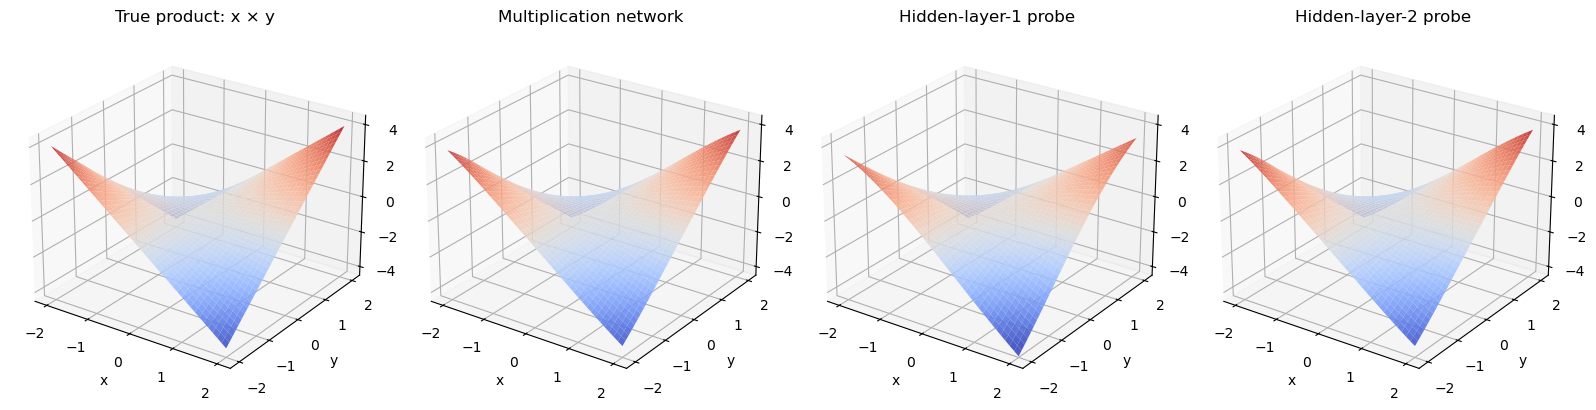

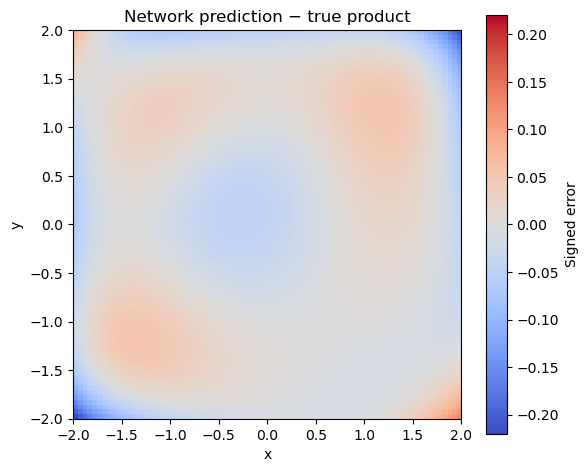

In [8]:
axis = torch.linspace(-2, 2, 81)
xx, yy = torch.meshgrid(axis, axis, indexing="xy")
grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)

with torch.no_grad():
    h1, h2 = model.activations(grid)
    surfaces = [product(grid), model(grid), probe1(h1), probe2(h2)]
    surfaces = [surface.reshape(xx.shape).numpy() for surface in surfaces]

fig = plt.figure(figsize=(16, 4))
for i, (title, surface) in enumerate(zip(
    ["True product: x × y", "Multiplication network", "Hidden-layer-1 probe", "Hidden-layer-2 probe"],
    surfaces,
)):
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    ax.plot_surface(xx.numpy(), yy.numpy(), surface, cmap="coolwarm",
                    vmin=-4, vmax=4, linewidth=0, alpha=0.9)
    ax.set(xlabel="x", ylabel="y", zlabel="Output", title=title, zlim=(-4.5, 4.5))
    ax.view_init(elev=25, azim=-55)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
error = surfaces[1] - surfaces[0]
limit = max(float(abs(error).max()), 1e-8)
plot = ax.imshow(error, origin="lower", extent=(-2, 2, -2, 2),
                 cmap="coolwarm", vmin=-limit, vmax=limit, aspect="equal")
ax.set(xlabel="x", ylabel="y", title="Network prediction − true product")
fig.colorbar(plot, ax=ax, label="Signed error")
plt.tight_layout()
plt.show()

Try changing the seed, number of training steps, or hidden activation and rerunning all cells. Compare overall test error, behavior along the zero-input axes, and first-layer probe fidelity. Probe weights depend on the learned representation and can change across runs, even when the output surface is similar.